In [23]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-22 13:38:24--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.2’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.05s   

2026-10-22 13:38:24 (5.18 MB/s) - ‘course_lead_scoring_2026.csv.2’ saved [278746/278746]



In [24]:
import pandas as pd
df=pd.read_csv('course_lead_scoring_2026.csv')
df.head(5)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [25]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [26]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [27]:
categorical=['lead_source','industry','employment_status','location']
numerical=['annual_income','number_of_courses_viewed','interaction_count','lead_score']
df[numerical]=df[numerical].fillna(0.0)
df[categorical]=df[categorical].fillna('NA')
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [28]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [30]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
#LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [31]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.651)

In [47]:
from sklearn.metrics import accuracy_score
accuracy_score(y_val, y_pred >= 0.5)

0.651

In [48]:
import numpy as np
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)     #threshold 0.6 is best

0.00 0.586
0.05 0.586
0.10 0.586
0.15 0.586
0.20 0.586
0.25 0.586
0.30 0.597
0.35 0.613
0.40 0.625
0.45 0.640
0.50 0.651
0.55 0.661
0.60 0.681
0.65 0.669
0.70 0.643
0.75 0.590
0.80 0.530
0.85 0.468
0.90 0.432
0.95 0.416
1.00 0.414


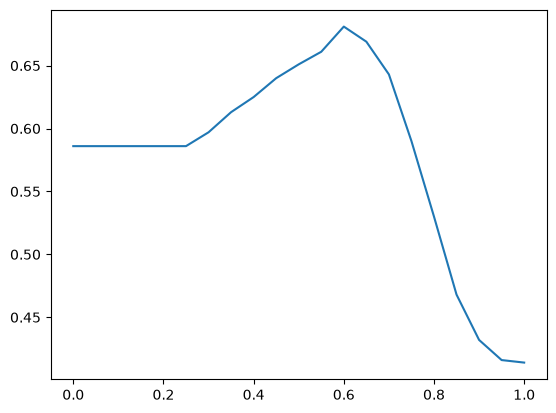

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
plt.plot(thresholds, scores)

In [35]:
from collections import Counter
print(Counter(y_pred >= 1.0))
print(1 - y_val.mean())

Counter({np.False_: 1000})
0.41400000000000003


In [41]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
t = 0.6
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()
print(tp,tn,fp,fn)
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

457 224 190 129


array([[224, 190],
       [129, 457]])

In [42]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.22, 0.19],
       [0.13, 0.46]])

In [43]:
p = tp / (tp + fp)
r = tp / (tp + fn)
print(p,r)

0.7063369397217929 0.7798634812286689


In [44]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)
tpr,fpr

(np.float64(0.7798634812286689), np.float64(0.45893719806763283))

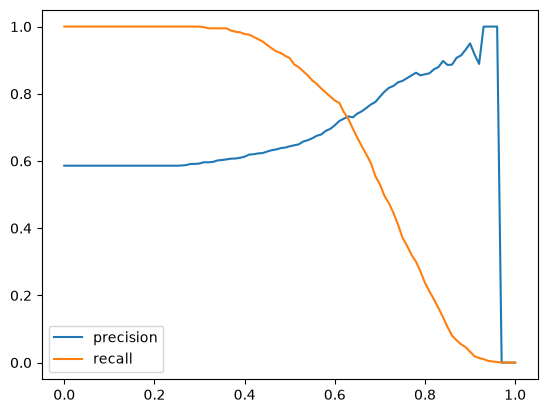

In [61]:
scores = []

thresholds = np.linspace(0, 1, 101)
f1=[]
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    precision=tp/(tp+fp) if (tp+fp)>0 else 0
    recall=tp/(tp+fn)

    f1_score=2*((precision*recall)/(precision+recall)) if (precision+recall)>0 else 0
    f1.append(f1_score)
    scores.append((t, tp, fp, fn, tn,recall,precision))
columns = ['threshold', 'tp', 'fp', 'fn', 'tn','recall','precision']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
plt.legend()

In [59]:
df_scores['diff'] = abs(df_scores['precision'] - df_scores['recall'])

df_scores = df_scores[
    ~((df_scores['precision'] == 0) & (df_scores['recall'] == 0))
]

df_scores.loc[df_scores['diff'].idxmin(), ['threshold', 'precision', 'recall', 'diff']]

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64

In [67]:
print(thresholds[f1.index(max(f1))],max(f1))

0.41000000000000003 0.7576158940397352


In [53]:
from sklearn.metrics import auc, roc_auc_score, roc_curve
print(roc_auc_score(y_train,df_train['annual_income']))
print(roc_auc_score(y_train,df_train['number_of_courses_viewed']))
print(roc_auc_score(y_train,df_train['interaction_count']))
print(roc_auc_score(y_train,df_train['lead_score']))

0.6081977776250831
0.7229894623989618
0.7649203047563227
0.7882254810906102


In [54]:
roc_auc_score(y_val,y_pred)

0.7318222288173319

In [71]:
from sklearn.model_selection import KFold
scores1=[]
kf= KFold(n_splits=5, shuffle=True, random_state=1)
for train_idx,val_idx in kf.split(df_full_train):
    train=df_full_train.iloc[train_idx]
    val=df_full_train.iloc[val_idx]
    
    train = train.reset_index(drop=True)
    val = val.reset_index(drop=True)

    new_train = train.converted.values
    new_val = val.converted.values

    train_features=train.drop(columns=['converted'])
    val_features=val.drop(columns=['converted'])
    dv = DictVectorizer(sparse=False)

    train_dict1 = train_features[categorical + numerical].to_dict(orient='records')
    X_train1 = dv.fit_transform(train_dict1)
    
    model1 = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model1.fit(X_train1, new_train)
    val_dict1 = val_features[categorical + numerical].to_dict(orient='records')
    X_val1 = dv.transform(val_dict1)
    
    y_pred1 = model1.predict_proba(X_val1)[:, 1]
    churn_decision = (y_pred1 >= 0.5)
    (new_val == churn_decision).mean()
    scores1.append(roc_auc_score(new_val,y_pred1))
print(scores1)
print(np.std(scores1).round(3))

[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
0.007


In [75]:
from sklearn.model_selection import KFold
scores2={0.000001:[],0.001:[], 1:[]}
kf= KFold(n_splits=5, shuffle=True, random_state=1)
for train_idx,val_idx in kf.split(df_full_train):
    train=df_full_train.iloc[train_idx]
    val=df_full_train.iloc[val_idx]
    
    train = train.reset_index(drop=True)
    val = val.reset_index(drop=True)

    new_train = train.converted.values
    new_val = val.converted.values

    train_features=train.drop(columns=['converted'])
    val_features=val.drop(columns=['converted'])
    dv = DictVectorizer(sparse=False)

    train_dict1 = train_features[categorical + numerical].to_dict(orient='records')
    X_train1 = dv.fit_transform(train_dict1)
    val_dict1 = val_features[categorical + numerical].to_dict(orient='records')
    X_val1 = dv.transform(val_dict1)
    
    for C in [0.000001, 0.001, 1]:
        model1 = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model1.fit(X_train1, new_train)
    
    
        y_pred1 = model1.predict_proba(X_val1)[:, 1]
        churn_decision = (y_pred1 >= 0.5)
        (new_val == churn_decision).mean()
        scores2[C].append(roc_auc_score(new_val,y_pred1))
        
print(scores2)
print((np.mean(scores2[0.000001]).round(3)),(np.std(scores2[0.000001]).round(3)))
print((np.mean(scores2[0.001]).round(3)),(np.std(scores2[0.001]).round(3)))
print((np.mean(scores2[1]).round(3)),(np.std(scores2[1]).round(3)))

{1e-06: [0.5941004654148612, 0.6402137243565715, 0.6001570384100505, 0.6364466933726896, 0.6127532038032245], 0.001: [0.7504349221633766, 0.7475333388395098, 0.7583539285346514, 0.7584127166669861, 0.7311259818106656], 1: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]}
0.617 0.019
0.749 0.01
0.732 0.007
